# Radiomics decisions for LIDC and LNDb

This notebook explains the settings for extracting radiomics from circles around nodule centroids and from nodule segmentations. We start with one axial slice.

The extraction scripts will generate the features and join them to the targets and patient folds created in [the malignancy notebook](malignancy_eda_splits_lidc_lndb.ipynb). For the competition, we use all 765 LNDb training nodules, including those smaller than 3 mm. Circle-versus-segmentation comparisons use the same nodules with available masks.

In [1]:
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pylidc as pl
from pylidc.utils import consensus
from radiomics.imageoperations import getBinEdges

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
LNDB_DIR = Path.home() / "Downloads/LNDb"
PROCESSED_DIR = ROOT / "data/processed"

lidc = pd.read_csv(PROCESSED_DIR / "lidc_annotations_clean.csv")
lndb_targets = pd.read_csv(PROCESSED_DIR / "lndb_nodule_targets.csv")
lndb_findings = pd.read_csv(LNDB_DIR / "allNods.csv")

CONSENSUS_LEVELS = [0.25, 0.50, 0.75, 1.00]

/home/jp/Documents/por-definir-ds/.venv/lib/python3.9/site-packages/pylidc/__init__.py:27: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources as _pr


## 1. Image values

As explained in [the preprocessing notebook](preprocess_lidc.ipynb), we will compare original HU values with clipping to `[-1000, 400]` during modelling. The extraction scripts will produce both feature versions, with `normalize: false`.

## 2. Pixel spacing

A fixed distance in millimetres can cover different numbers of pixels across scans. We summarize the original spacing, counting each scan once. For LNDb, only the small `.mhd` headers are read from the ZIP files.

In [2]:
lidc_spacing = lidc.drop_duplicates("series_uid")["pixel_spacing"]

lndb_spacing = []
for lndb_id in sorted(lndb_targets["LNDbID"].unique()):
    scan_name = f"LNDb-{lndb_id:04d}"
    with ZipFile(LNDB_DIR / f"{scan_name}.zip") as archive:
        header = archive.read(f"{scan_name}.mhd").decode()
    line = next(line for line in header.splitlines() if line.startswith("ElementSpacing"))
    spacing = [float(value) for value in line.split("=")[1].split()]
    lndb_spacing.append(spacing[:2])

lndb_spacing = pd.DataFrame(lndb_spacing, columns=["x", "y"])
spacing_summary = pd.DataFrame({
    "LIDC x-y": lidc_spacing.quantile([0, 0.25, 0.5, 0.75, 1]),
    "LNDb x": lndb_spacing["x"].quantile([0, 0.25, 0.5, 0.75, 1]),
    "LNDb y": lndb_spacing["y"].quantile([0, 0.25, 0.5, 0.75, 1]),
}).T
spacing_summary.columns = ["minimum", "25%", "median", "75%", "maximum"]
spacing_summary.round(3)

,minimum,25%,median,75%,maximum
LIDC x-y,0.461,0.625,0.703,0.742,0.977
LNDb x,0.433,0.577,0.648,0.699,0.895
LNDb y,0.433,0.577,0.648,0.699,0.895


The median in-plane spacing is about `0.70 mm` in LIDC and `0.65 mm` in LNDb. We choose `0.7 × 0.7 mm` as a common spacing close to both datasets. For one-slice extraction, `resampledPixelSpacing: [0.7, 0.7, 0]` keeps the original spacing through the slice direction.

We keep cubic B-spline interpolation (`sitkBSpline`), the PyRadiomics default, for CT images. PyRadiomics uses nearest-neighbour interpolation for masks to preserve their labels. These settings remain fixed across experiments ([PyRadiomics documentation](https://pyradiomics.readthedocs.io/en/latest/customization.html#feature-extractor-level)).

## 3. Region and slice selection

- **Circle:** centre it on the supplied nodule coordinate and use the nearest axial slice.
- **Segmentation:** use the axial slice with the largest mask area.

We pass one CT slice to PyRadiomics with these settings:

```yaml
force2D: true         # Calculate texture in two dimensions.
force2Ddimension: 0   # Exclude the direction between CT slices.
```

Our image array is ordered as **`[slice, row, column]`**. Dimension `0` means the first axis, **slice**. Excluding that axis means neighbouring pixels can differ in row and column, but must stay in the same slice. The `0` identifies a direction, not a slice number.

### Circle radius values

We use size percentiles to suggest radius values. For LIDC, the size estimate is half the largest reader diameter. For LNDb, it is half the equivalent diameter. P95 means that 95% of these estimates are at or below that value. These estimates do not guarantee full coverage of a nodule by a circle.

The table uses **all 765 LNDb training nodules** and shows **P95, P97 and P99**. The 143 point-only nodules have no measured diameter. Their `DiamEq_Rad = 3` marker is represented as an upper bound of 1.5 mm for the radius estimate. All three percentiles lie above this bound, so their values come from the measured nodules while the counts include every nodule. The histogram shows all three percentile-based radius values for each dataset, rounded up to whole millimetres.

In [11]:
lidc_radius = lidc.groupby(["patient_id", "series_uid", "nodule_id"])["diameter"].max() / 2
lndb_sizes = lndb_targets[["LNDbID", "NoduleID"]].merge(
    lndb_findings.rename(columns={"FindingID": "NoduleID"}),
    on=["LNDbID", "NoduleID"],
    validate="one_to_one",
)
# For point-only nodules, 1.5 mm is an upper bound rather than a measurement.
lndb_radius = lndb_sizes["DiamEq_Rad"] / 2

radius_summary = pd.DataFrame({
    "LIDC": lidc_radius.quantile([0.95, 0.97, 0.99]),
    "LNDb all sizes": lndb_radius.quantile([0.95, 0.97, 0.99]),
}).T
radius_summary.columns = ["P95 (mm)", "P97 (mm)", "P99 (mm)"]
radius_summary.insert(0, "Nodules", [len(lidc_radius), len(lndb_radius)])

# Round up P99 for the table.
radius_summary["P99 rounded up (mm)"] = np.ceil(radius_summary["P99 (mm)"]).astype(int)
radius_summary.round(2)

,Nodules,P95 (mm),P97 (mm),P99 (mm),P99 rounded up (mm)
LIDC,2637,13.93,16.42,20.37,21
LNDb all sizes,765,5.69,6.72,10.93,11


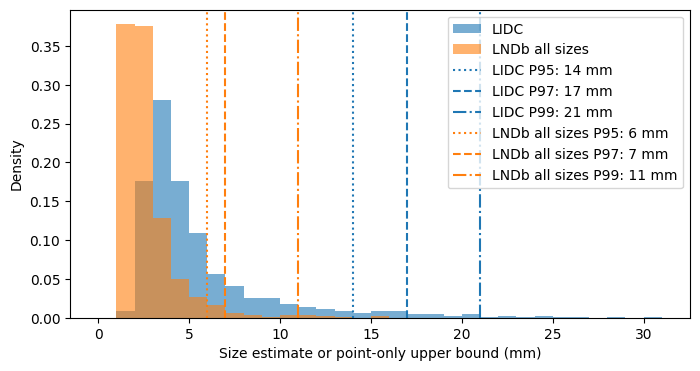

In [13]:
bins = np.arange(0, np.ceil(max(lidc_radius.max(), lndb_radius.max())) + 1, 1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(lidc_radius, bins=bins, density=True, alpha=0.6, label="LIDC")
ax.hist(lndb_radius, bins=bins, density=True, alpha=0.6, label="LNDb all sizes")
for dataset, color in [("LIDC", "tab:blue"), ("LNDb all sizes", "tab:orange")]:
    for percentile, style in [("P95", ":"), ("P97", "--"), ("P99", "-.")]:
        radius = int(np.ceil(radius_summary.loc[dataset, f"{percentile} (mm)"]))
        ax.axvline(radius, color=color, linestyle=style, label=f"{dataset} {percentile}: {radius} mm")
ax.set(xlabel="Size estimate or point-only upper bound (mm)", ylabel="Density")
ax.legend()
plt.show()

We will compare two ways of choosing the radius at **P95, P97 and P99**:

- **Shared radius:** use the LNDb percentile for both datasets.
- **Dataset-specific radius:** use the same percentile, calculated separately for LIDC and LNDb.

The full training datasets give these radius values, rounded up to whole millimetres:

| Percentile | Shared: LIDC / LNDb | Dataset-specific: LIDC / LNDb |
|---|---|---|
| P95 | 6 / 6 mm | 14 / 6 mm |
| P97 | 7 / 7 mm | 17 / 7 mm |
| P99 | 11 / 11 mm | 21 / 11 mm |

This tests whether adapting the radius to each dataset's nodule sizes improves the model. Larger circles include more surrounding tissue, but do not guarantee a fixed perinodular margin. Each configuration will be compared with and without clipping.

During validation, calculate percentiles from the training patients only and apply the resulting radius values to the held-out patients. The competition test set uses the selected percentile and radius determined from the LNDb training data.

### LIDC consensus levels

LIDC has one mask per reader. The consensus level is the fraction of readers who must include a pixel for it to remain in the combined mask. We will compare **0.25, 0.50, 0.75 and 1.00**.

The example below has four readers. We show the same slice at each level to make the change in the mask visible. During extraction, each mask uses its own largest-area slice. The lung window is only for displaying the image.

In [4]:
example = lidc[lidc["n_readers_in_cluster"] == 4].iloc[0]
scan = pl.query(pl.Scan).filter(pl.Scan.series_instance_uid == example["series_uid"]).one()
annotations = scan.cluster_annotations()[int(example["nodule_id"])]
mask, bbox, reader_masks = consensus(annotations, clevel=0.50, pad=[(20, 20), (20, 20), (0, 0)])

volume = scan.to_volume(verbose=False)
slice_index = mask.sum(axis=(0, 1)).argmax()
image_slice = volume[bbox][:, :, slice_index].copy()
roi_values = image_slice[mask[:, :, slice_index]]
agreement = np.mean(reader_masks, axis=0)[:, :, slice_index]
del volume

print(f"{example['patient_id']}, nodule {example['nodule_id']}")

LIDC-IDRI-0078, nodule 0


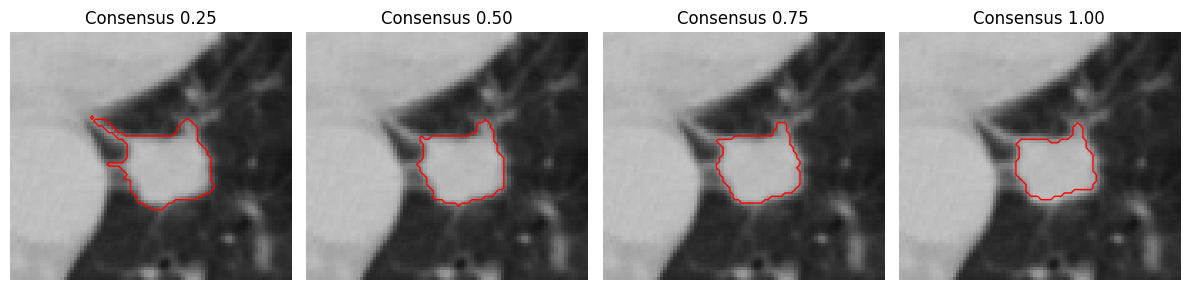

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, level in zip(axes, CONSENSUS_LEVELS):
    ax.imshow(image_slice, cmap="gray", vmin=-1000, vmax=400)
    ax.contour(agreement >= level, levels=[0.5], colors="red", linewidths=1)
    ax.set_title(f"Consensus {level:.2f}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Bin width

Texture features group intensity values into bins. A fixed bin width keeps the same HU difference per bin across nodules. A smaller width preserves finer intensity differences, while a larger width groups more values together.

The histograms show **10, 25 and 50 HU** bins using the original values inside the example segmentation. PyRadiomics mentions roughly 30–130 bins as practical guidance, while noting that there is no universally optimal width ([discretization documentation](https://pyradiomics.readthedocs.io/en/latest/faq.html#what-about-gray-value-discretization-fixed-bin-width-fixed-bin-count)).

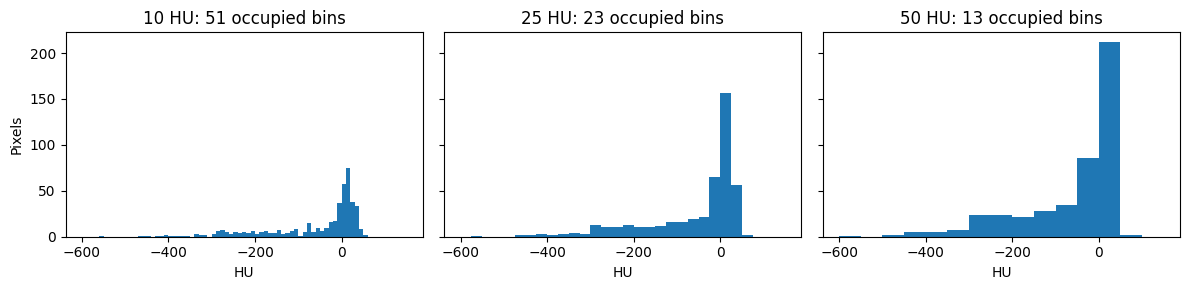

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharex=True, sharey=True)
for ax, width in zip(axes, [10, 25, 50]):
    edges = getBinEdges(roi_values, binWidth=width)
    counts, _ = np.histogram(roi_values, bins=edges)
    ax.hist(roi_values, bins=edges)
    ax.set(title=f"{width} HU: {np.count_nonzero(counts)} occupied bins", xlabel="HU")
axes[0].set_ylabel("Pixels")
plt.tight_layout()
plt.show()

We use **`binWidth: 25`**, the PyRadiomics default, as a fixed baseline. This example illustrates the effect of bin width, rather than establishing an optimal value for all nodules.

## 5. Features and image filters

We extract the non-deprecated features from **First Order, GLCM, GLRLM, GLSZM, GLDM and NGTDM**. `shape2D` is included for segmentation masks. It is excluded for fixed circles because their shape is defined by the chosen radius.

We use the following image types provided by PyRadiomics: **Original, Wavelet, Square, SquareRoot, Logarithm, Exponential, Gradient and LBP2D** ([available filters](https://pyradiomics.readthedocs.io/en/latest/customization.html#image-types)).

**LoG is excluded from the one-slice method because the PyRadiomics implementation requires a 3D image with at least four voxels in every dimension** ([LoG documentation](https://pyradiomics.readthedocs.io/en/latest/radiomics.html#radiomics.imageoperations.getLoGImage)). `LBP3D` and 3D shape features are also excluded from this 2D extraction.

Feature selection will be fitted using training folds only.

## 6. Extraction plan

### Fixed extraction settings

| Setting | What we do |
|---|---|
| Pixel size | Resample to 0.7 × 0.7 mm within the slice |
| Image interpolation | Cubic B-spline, the PyRadiomics default |
| Mask interpolation | Nearest neighbour, keeping the mask binary |
| Normalization | None |
| Texture | Compare neighbouring pixels within the selected slice |
| Bin width | Group intensity values into 25 HU intervals for texture calculation |
| Shape features | Include `shape2D` for segmentations only |

### Choices compared during modelling

| Choice | Options |
|---|---|
| Image values | Original HU or clipping to `[-1000, 400]` |
| Region | Circle or nodule segmentation |
| Circle radius | P95, P97 or P99, using a shared LNDb-based radius or dataset-specific radius values |
| LIDC reader agreement | 25%, 50%, 75% or 100% |

Circles use the slice nearest the centroid. Segmentations use the slice with the largest mask area.

The extraction scripts will produce the feature versions listed above. Their performance will be compared during modelling using the saved patient folds. Clipping, radius and consensus choices are selected through training-fold validation.

### Later comparison: 2D versus 3D

We also plan to test 3D extraction using spheres around centroids or full segmentation volumes, with the same nodules and patient folds as the 2D comparison. This will use a separate 3D configuration with `force2D: false`. LoG can then be considered.